In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import math
import os
import os.path
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import plotnine as pn
import shapely
import scipy
import xarray as xr

from shoreshop3_analysis import util, data, wct, wavelet, transect_loaders, plot

In [35]:
ds = xr.open_zarr(data.global_coherence_path, consolidated=False)
ds

<xarray.Dataset> Size: 58MB
Dimensions:    (model: 43, transect: 970, scale: 87)
Coordinates:
  * model      (model) <U28 5kB 'BRIE' 'CCOST.DESM.recon' ... 'Traboulsi'
  * transect   (transect) <U9 35kB '0001_0001' '0001_0010' ... '0049_0229'
  * scale      (scale) int64 696B 0 1 2 3 4 5 6 7 8 ... 79 80 81 82 83 84 85 86
Data variables:
    period     (model, transect, scale) float64 29MB dask.array<chunksize=(1, 1, 87), meta=np.ndarray>
    coherence  (model, transect, scale) float64 29MB dask.array<chunksize=(1, 1, 87), meta=np.ndarray>
Attributes:
    title:    
    source:

In [36]:
len(np.array((~np.isnan(ds.period[:, :, 0].values)).nonzero()).T)

25286

In [37]:
ds.period[1, 0, :].values == ds.period[1, 1, :].values

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False])

In [38]:
coh = ds.coherence.values
coh

array([[[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        ...,
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[0.36095121, 0.35111551, 0.34288224, ...,        nan,
                nan,        nan],
        [0.30330816, 0.26594817, 0.22705958, ...,        nan,
                nan,        nan],
        [0.32349948, 0.30688529, 0.30192223, ...,        nan,
                nan,        nan],
        ...,
        [0.27816777, 0.28080121, 0.29026911, ...,        nan,
                nan,        nan],
        [0.3

In [39]:
coh[coh < 0] = np.nan
coh[coh > 1] = np.nan

In [46]:
mean = np.nanmean(coh, axis=1)
mean

/tmp/ipykernel_2529584/3444397126.py:1: RuntimeWarning: Mean of empty slice


array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [0.29900346, 0.27261279, 0.25135927, ...,        nan,        nan,
               nan],
       [0.31659488, 0.29675013, 0.2808026 , ...,        nan,        nan,
               nan],
       ...,
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]], shape=(43, 87))

In [47]:
mean[1]

array([0.29900346, 0.27261279, 0.25135927, 0.23370977, 0.21842919,
       0.20006629, 0.18892198, 0.18065781, 0.17636998, 0.17144628,
       0.17326038, 0.17634464, 0.17932556, 0.17832397, 0.17988219,
       0.17799865, 0.17899794, 0.18050576, 0.18029265, 0.18312047,
       0.18280134, 0.18372191, 0.18301683, 0.18623308, 0.18945822,
       0.1920934 , 0.19427492, 0.19418862, 0.19400594, 0.19392878,
       0.19464081, 0.19238028, 0.18724276, 0.18000582, 0.17176836,
       0.16686726, 0.16449923, 0.16345974, 0.16114023, 0.15955709,
       0.15622141, 0.15237363, 0.14396673, 0.13212291, 0.1216555 ,
       0.11970629, 0.13155061, 0.15226509, 0.16609477, 0.16295313,
       0.15129062, 0.14968674, 0.16340101, 0.18255179, 0.19550906,
       0.19595488, 0.18611291, 0.17779559, 0.18349576, 0.20541914,
       0.2384227 ,        nan,        nan,        nan,        nan,
              nan,        nan,        nan,        nan,        nan,
              nan,        nan,        nan,        nan,        

In [48]:
period_mask = ~np.isnan(mean).all(axis=0)
mean = mean[:, period_mask]
mean

array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [0.29900346, 0.27261279, 0.25135927, ..., 0.18349576, 0.20541914,
        0.2384227 ],
       [0.31659488, 0.29675013, 0.2808026 , ..., 0.35223497, 0.34310759,
        0.33459954],
       ...,
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]], shape=(43, 61))

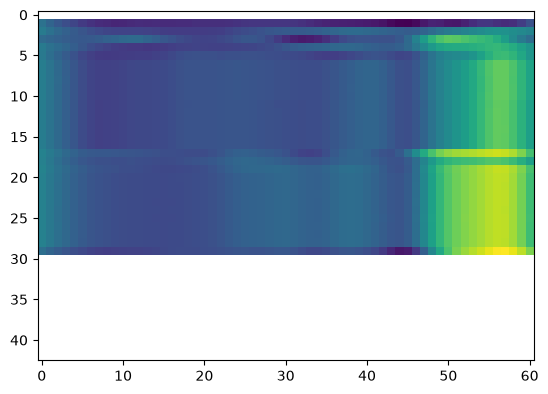

In [49]:
plt.imshow(mean, cmap='viridis')

In [50]:
np.min(mean[~np.isnan(mean)]), np.max(mean[~np.isnan(mean)])

(np.float64(0.11970628908245777), np.float64(0.5947067879278116))

In [51]:
mean.shape

(43, 61)

In [52]:
mean_tosort = mean.copy()
mean_tosort[np.isnan(mean_tosort)] = 0
order = np.argsort(mean_tosort, axis=0)[::-1]
rank = np.argsort(order, axis=0)
rank

array([[42, 42, 42, ..., 42, 42, 42],
       [26, 28, 28, ..., 28, 28, 28],
       [23, 24, 24, ..., 26, 26, 26],
       ...,
       [35, 35, 35, ..., 35, 35, 35],
       [36, 36, 36, ..., 36, 36, 36],
       [37, 37, 37, ..., 37, 37, 37]], shape=(43, 61))

In [53]:
df = pd.DataFrame({
    'model': np.repeat(ds.model.values, mean.shape[1]),
    'period': np.tile(ds.period[1, 0, period_mask].values, mean.shape[0]),
    'coherence': mean.flatten(),
    'rank': rank.flatten(),
})

df

,model,period,coherence,rank
0,BRIE,16.000000,NaN,42
1,BRIE,16.951410,NaN,42
2,BRIE,17.959393,NaN,42
3,BRIE,19.027314,NaN,42
4,BRIE,20.158737,NaN,42
...,...,...,...,...
2618,Traboulsi,406.374669,NaN,37
2619,Traboulsi,430.538965,NaN,37
2620,Traboulsi,456.140144,NaN,37
2621,Traboulsi,483.263648,NaN,37


In [54]:
df[df['model'] == 'Mao.GraphShore']

,model,period,coherence,rank
2501,Mao.GraphShore,16.000000,NaN,36
2502,Mao.GraphShore,16.951410,NaN,36
2503,Mao.GraphShore,17.959393,NaN,36
2504,Mao.GraphShore,19.027314,NaN,36
2505,Mao.GraphShore,20.158737,NaN,36
...,...,...,...,...
2557,Mao.GraphShore,406.374669,NaN,36
2558,Mao.GraphShore,430.538965,NaN,36
2559,Mao.GraphShore,456.140144,NaN,36
2560,Mao.GraphShore,483.263648,NaN,36


/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 8 x 8 in image.
/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ../figures/mean-coherence.png


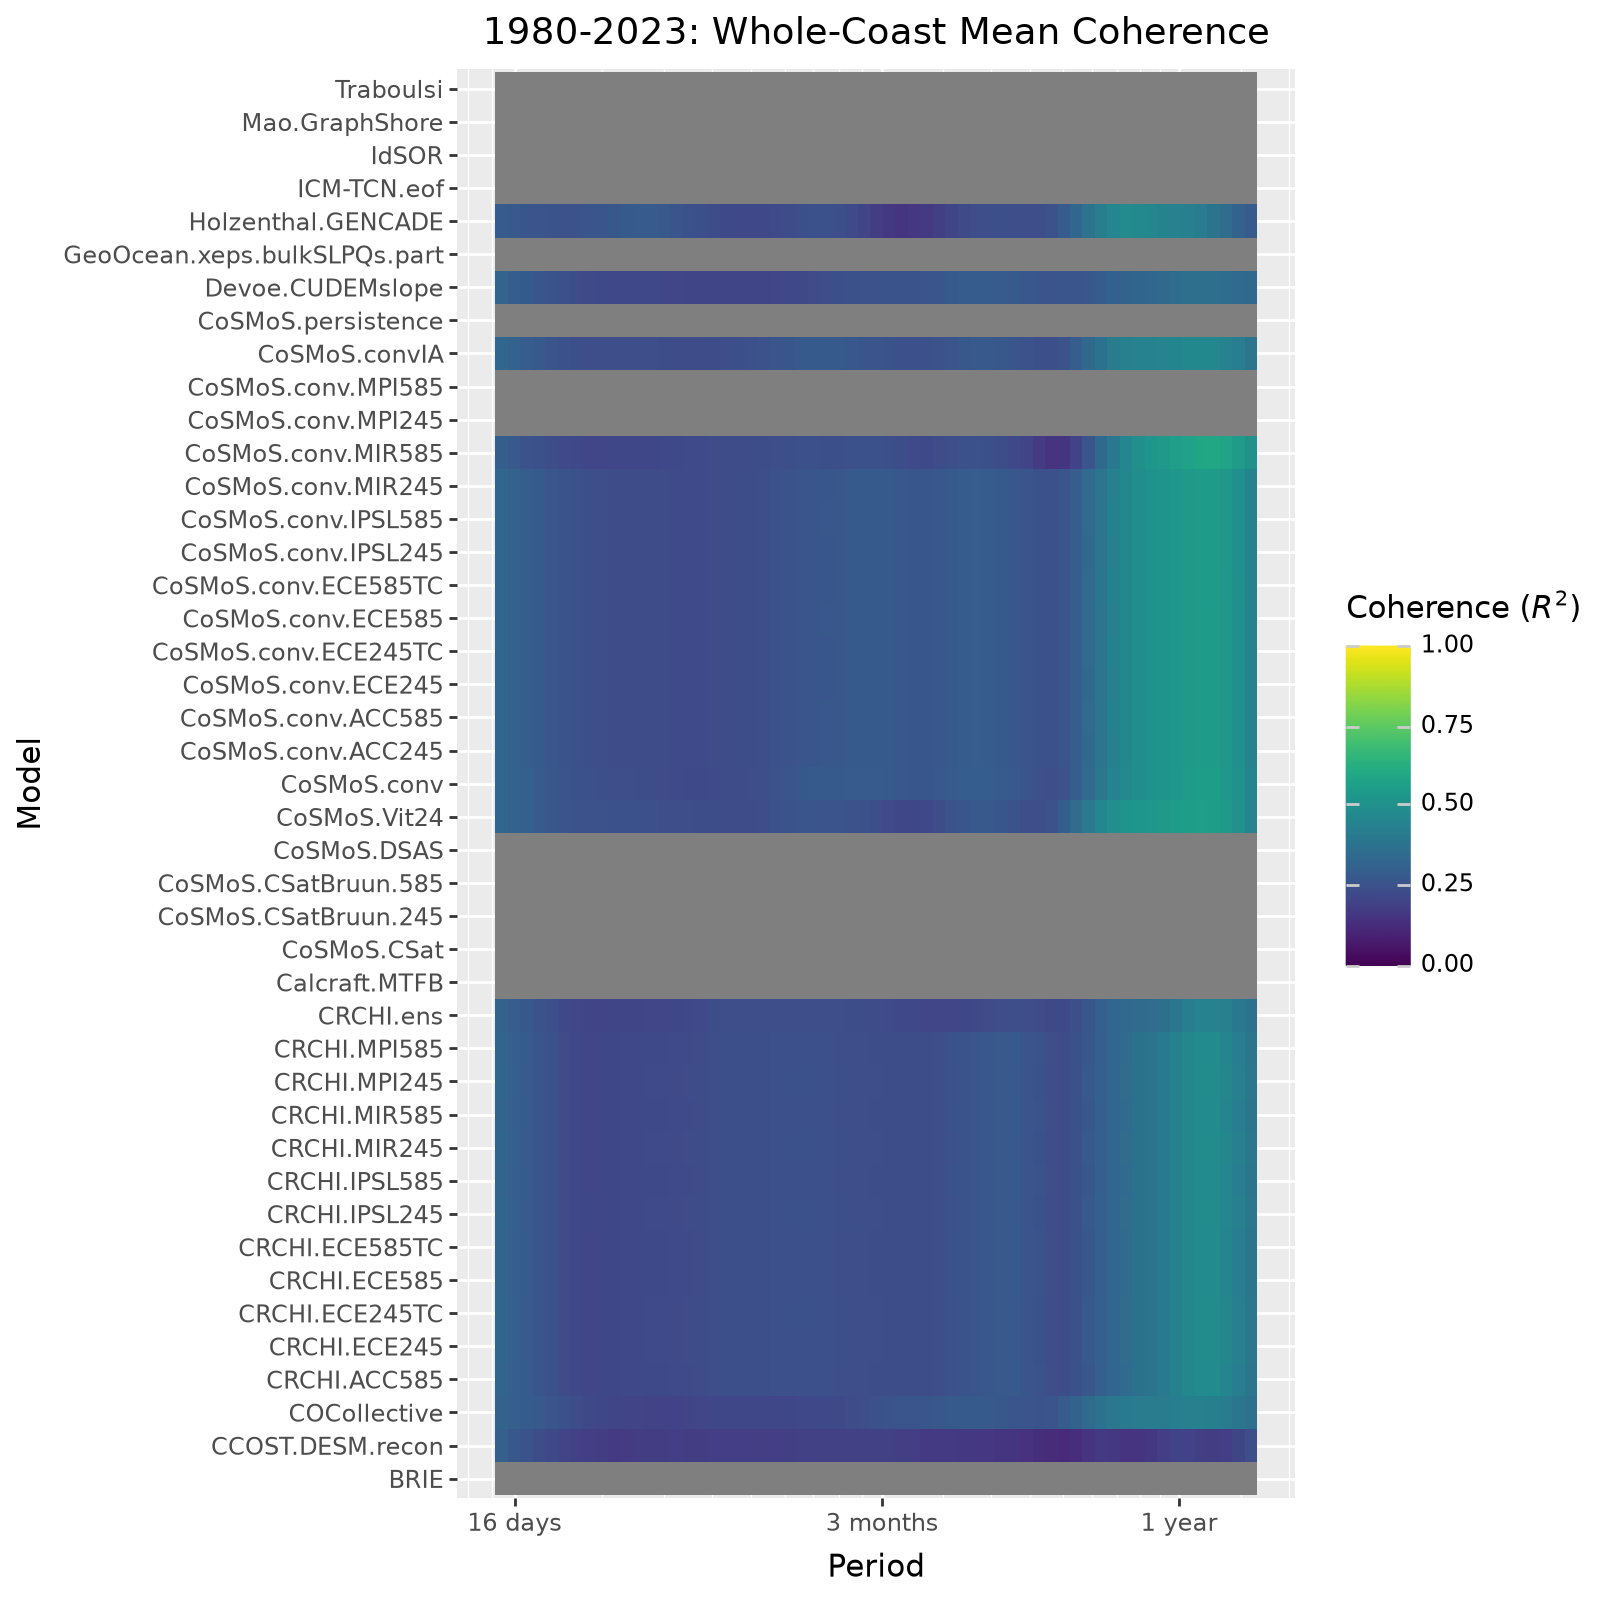

In [55]:
p = (
    pn.ggplot(df)
    + pn.geom_tile(pn.aes('period', 'model', fill='coherence'))
    + pn.scale_x_log10(
        breaks=[2, 17, 31*3, 367, 366*4, 366*14],
        labels=lambda breaks: list(map(wavelet.format_period, breaks)),
    )
    + pn.scale_fill_continuous(limits=(0, 1), cmap_name='viridis')
    + pn.labs(x='Period', y='Model', title='1980-2023: Whole-Coast Mean Coherence', fill='Coherence ($R^2$)')
    + pn.theme(figure_size=(8, 8))
)
p.save('../figures/mean-coherence.png', dpi=180)
p

In [56]:
df_nonan = df[~df['coherence'].isna().groupby(df['model']).transform('all')]
#df_nonan['rank'] = np.minimum(df_nonan['rank'].values, len(df_nonan['model'].unique()))
# df_nonan = df_nonan[df_nonan['period'].isin(df_nonan['period'].unique()[::2])]
mean_rank = df_nonan['rank'].groupby(df['model']).mean().argsort().argsort()
k = 10
topk = mean_rank[mean_rank < k]
print(topk.index.unique())
df_nonan = df_nonan[df_nonan['model'].isin(topk.index)]
df_nonan['rank'] = df_nonan.groupby('period')['coherence'].rank(method='first', ascending=False).astype(int) - 1
df_nonan

Index(['CoSMoS.Vit24', 'CoSMoS.conv', 'CoSMoS.conv.ACC245',
       'CoSMoS.conv.ACC585', 'CoSMoS.conv.ECE245', 'CoSMoS.conv.ECE245TC',
       'CoSMoS.conv.ECE585TC', 'CoSMoS.conv.IPSL245', 'CoSMoS.conv.IPSL585',
       'CoSMoS.conv.MIR245'],
      dtype='str', name='model')


,model,period,coherence,rank
1037,CoSMoS.Vit24,16.000000,0.330180,1
1038,CoSMoS.Vit24,16.951410,0.313908,0
1039,CoSMoS.Vit24,17.959393,0.297887,0
1040,CoSMoS.Vit24,19.027314,0.282763,1
1041,CoSMoS.Vit24,20.158737,0.270466,1
...,...,...,...,...
1764,CoSMoS.conv.MIR245,406.374669,0.549088,9
1765,CoSMoS.conv.MIR245,430.538965,0.546392,9
1766,CoSMoS.conv.MIR245,456.140144,0.528867,9
1767,CoSMoS.conv.MIR245,483.263648,0.495809,8


/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ../figures/topk-ranks.png


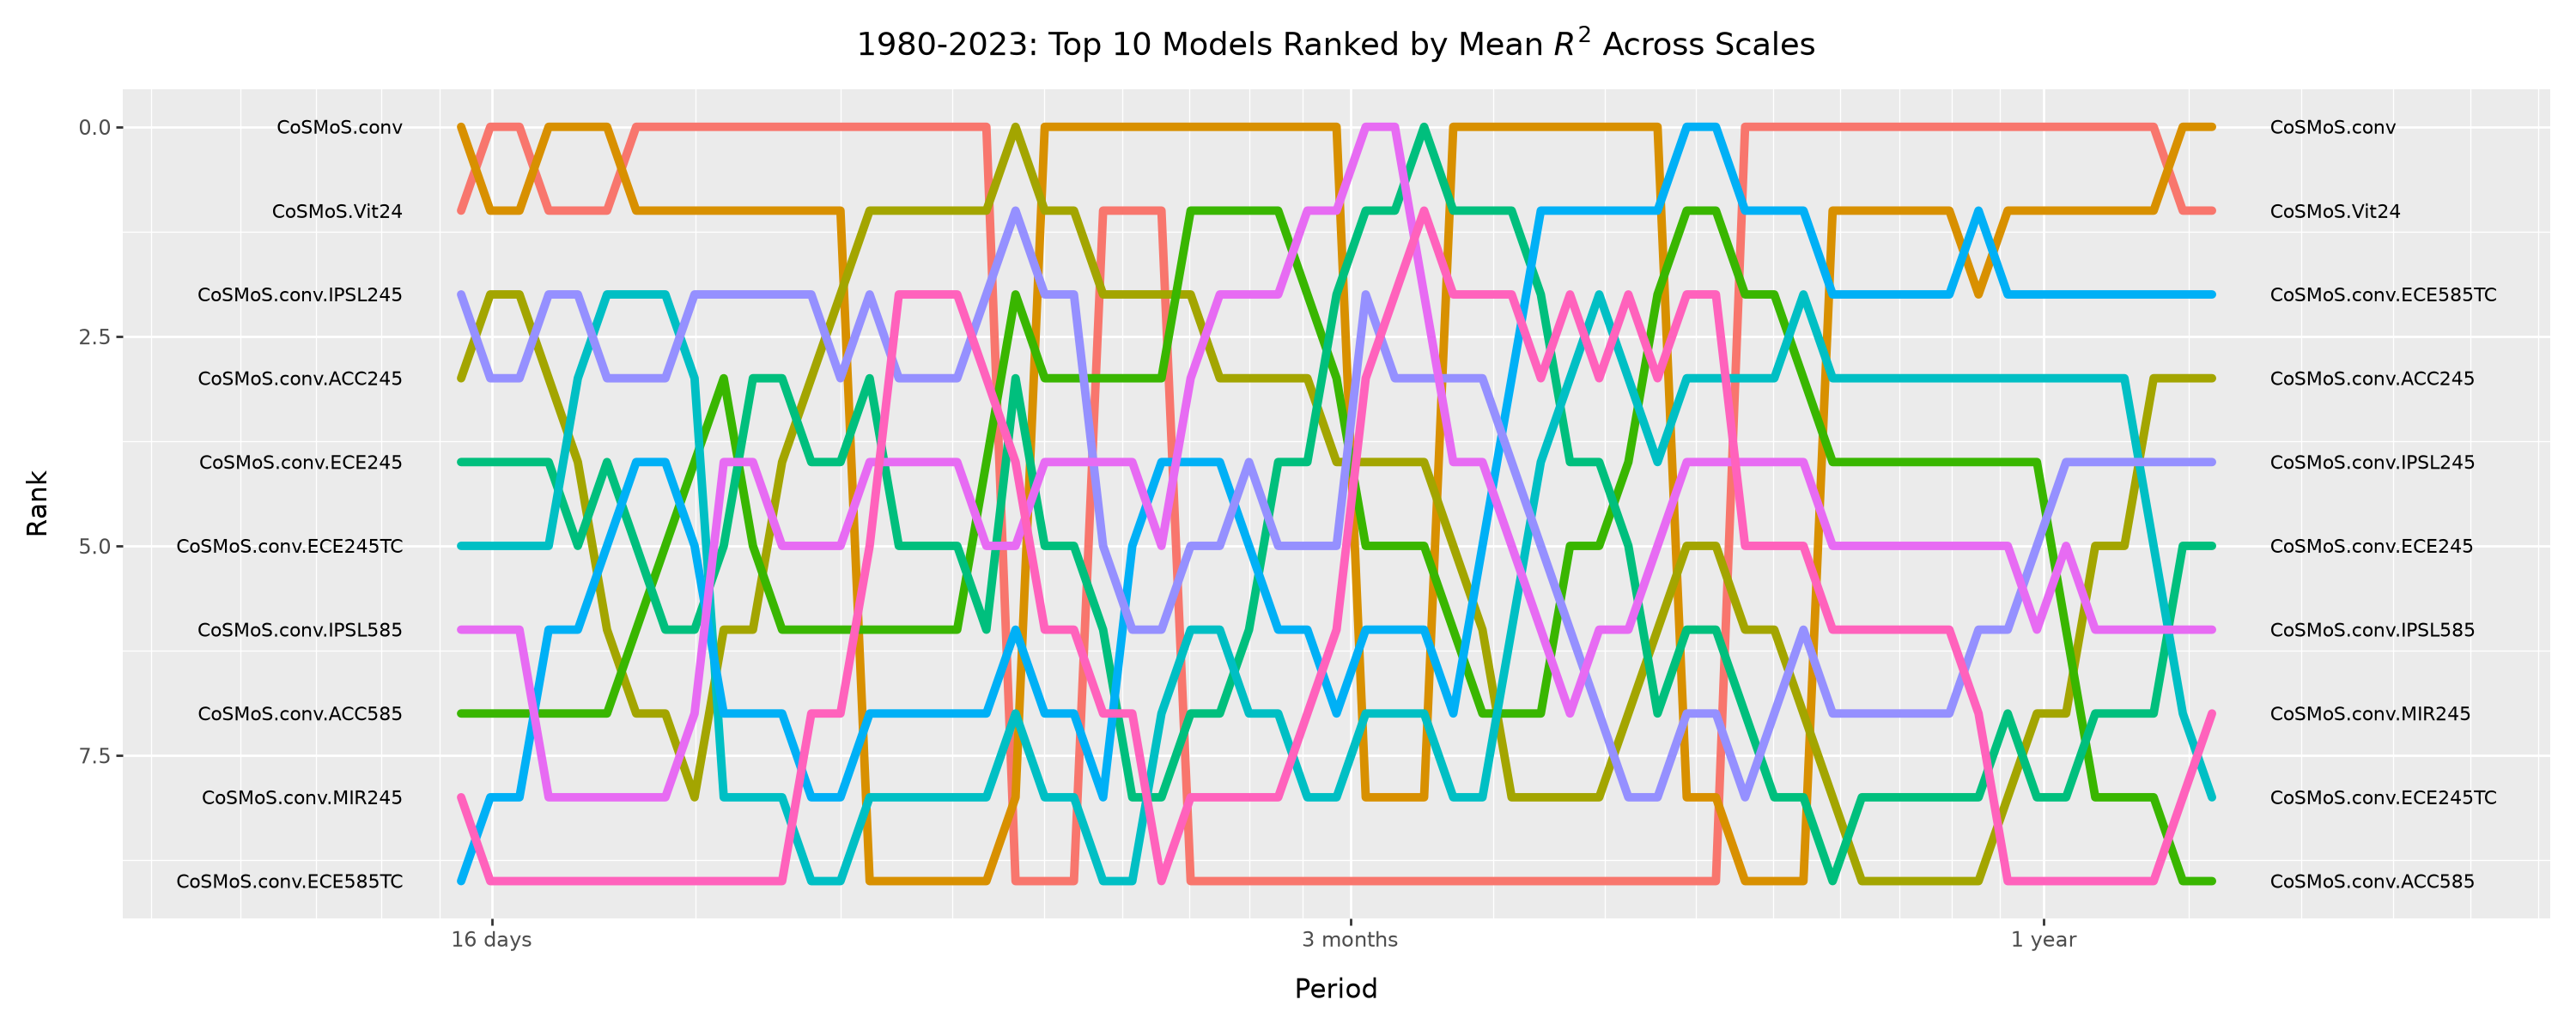

In [57]:
p = (
    pn.ggplot(df_nonan)
    + pn.geom_path(
        pn.aes('period', 'rank', group='model', color='model'),
        size=2,
        lineend='round',
    )
    + pn.geom_text(
        pn.aes('period', 'rank', label='model'),
        data=df_nonan[df_nonan['period'] == df_nonan['period'].min()],
        ha='right',
        size=8,
        nudge_x=-0.05,
    )
    + pn.geom_text(
        pn.aes('period', 'rank', label='model'),
        data=df_nonan[df_nonan['period'] == df_nonan['period'].max()],
        ha='left',
        size=8,
        nudge_x=0.05,
    )
    + pn.scale_x_log10(
        breaks=[2, 17, 31*3, 367, 366*4, 366*14],
        labels=lambda breaks: list(map(wavelet.format_period, breaks)),
        expand=(0.15, 0, 0.15, 0),
    )
    + pn.scale_y_reverse()
    #+ pn.scale_fill_hue()
    + pn.labs(x='Period', y='Rank', fill='Model', title=f'1980-2023: Top {k} Models Ranked by Mean $R^2$ Across Scales')
    + pn.theme(figure_size=(15, 6), legend_position='none')
)
p.save('../figures/topk-ranks.png')
p